# 1.Entendimento do Problema 

Qual o problema: Prever a demanda futura de milhares de produtos vendidos em lojas do Walmart (M5), em diferentes estados e categorias.
Qual o objetivo : Construir modelos que projetem as vendas diárias dos próximos 28 dias por item/loja.
Qual o paradigma de DS : Forecasting (previsão de série temporal, não regressão tabular tradicional).
Quais os algoritmos de ml será utilizado : Baseline (naive/média móvel), ETS/SARIMA, LightGBM com lags e, depois, comparação com deep learning/foundation models.

# 2.Carregando bibliotecas e o dataset 

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)

# Diferente de dataset tabular comum, aqui a informação vem espalhada em 3 tabelas
sales = pd.read_csv("data/m5-forecasting-accuracy/sales_train_evaluation.csv")
calendar = pd.read_csv("data/m5-forecasting-accuracy/calendar.csv")
prices = pd.read_csv("data/m5-forecasting-accuracy/sell_prices.csv")

d_cols = [c for c in sales.columns if c.startswith('d_')]
sales[d_cols] = sales[d_cols].astype('int16')  # 30.490 x 1.941 em int64 pesaria demais

# 3.EDA(Análise Exploratória dos Dados)

Entendendo a estrutura dos dados 

In [2]:
print("sales   :", sales.shape)
print("calendar:", calendar.shape)
print("prices  :", prices.shape)
print()
print(sales.dtypes.value_counts())

sales   : (30490, 1947)
calendar: (1969, 14)
prices  : (6841121, 4)

int16    1941
str         6
Name: count, dtype: int64


In [3]:
sales.iloc[:5, :10]  # id + metadados + primeiros dias (formato wide: 1 coluna por dia)

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0


In [4]:
calendar.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [5]:
prices.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


A `sales` está em formato **wide** (cada dia é uma coluna, `d_1` a `d_1941`) — diferente do formato long/tidy comum em dataset tabular. `calendar` traduz cada `d_x` numa data real e traz eventos/feriados. `prices` traz o preço por loja/semana (`wm_yr_wk`). Fazer o *melt* das 30.490 séries inteiras de uma vez estoura a memória (vira ~59 milhões de linhas) — a estratégia abaixo usa agregação direto no wide quando possível, e melt só numa amostra quando precisa analisar série a série.

Auditoria de qualidade dos dados.

In [6]:
print("Duplicatas em sales:", sales.duplicated().sum())
print("Duplicatas em calendar:", calendar.duplicated().sum())
print("Duplicatas em prices:", prices.duplicated().sum())
print()
print("Nulos em calendar:")
print(calendar.isnull().sum())

Duplicatas em sales: 0
Duplicatas em calendar: 0


Duplicatas em prices: 0

Nulos em calendar:
date               0
wm_yr_wk           0
weekday            0
wday               0
month              0
year               0
d                  0
event_name_1    1807
event_type_1    1807
event_name_2    1964
event_type_2    1964
snap_CA            0
snap_TX            0
snap_WI            0
dtype: int64


Os nulos em `event_name_1/2` e `event_type_1/2` não são dado faltante real — significam apenas "não houve evento nesse dia" (a maioria dos dias não tem feriado/evento especial). `sales` e `prices` não têm nulos nem duplicatas.

Comportamento geral da demanda (visão agregada, sem melt)

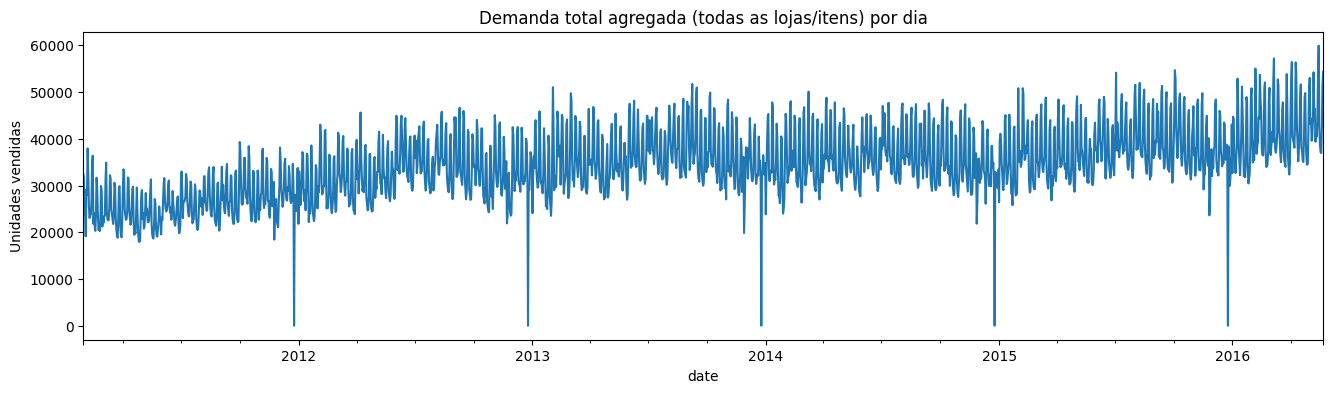

In [7]:
datas = pd.to_datetime(calendar.set_index('d').loc[d_cols, 'date'])
demanda_total = sales[d_cols].sum(axis=0)
demanda_total.index = datas

plt.figure(figsize=(16, 4))
demanda_total.plot()
plt.title("Demanda total agregada (todas as lojas/itens) por dia")
plt.ylabel("Unidades vendidas")
plt.show()

Existe tendência de crescimento ao longo dos ~5 anos e sazonalidade semanal visível (oscilação constante). Os vales mais profundos e recorrentes coincidem com o Natal (loja fechada em 25/dez todos os anos) — um padrão que qualquer modelo de forecasting precisa capturar, seja via variável de calendário, seja tratando como outlier conhecido.

Verificando a distribuição e a intermitência da demanda (target)

count    5.918109e+07
mean     1.130888e+00
std      3.870038e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      1.000000e+00
max      7.630000e+02
dtype: float64


Assimetria (skewness): 17.12
% de dias com venda zero: 68.0%


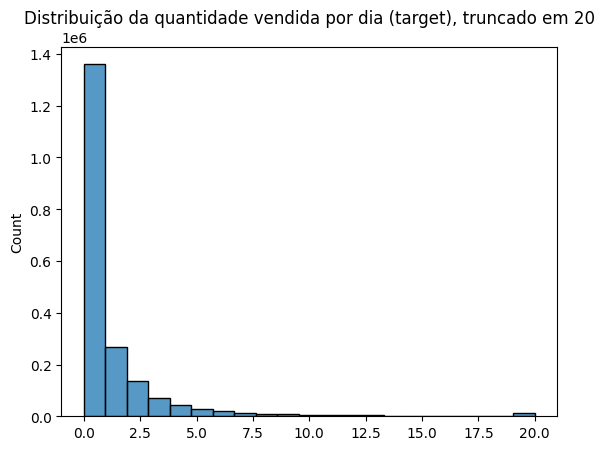

In [8]:
valores = sales[d_cols].to_numpy().ravel()

print(pd.Series(valores).describe())
print(f"Assimetria (skewness): {pd.Series(valores).skew():.2f}")
print(f"% de dias com venda zero: {(valores == 0).mean()*100:.1f}%")

amostra_plot = np.random.default_rng(42).choice(valores, size=2_000_000, replace=False)
sns.histplot(np.clip(amostra_plot, 0, 20), bins=21)
plt.title("Distribuição da quantidade vendida por dia (target), truncado em 20")
plt.show()

Diferente de um target contínuo típico de regressão, aqui a variável é uma contagem com forte concentração em zero (demanda intermitente) — comum em catálogos grandes, onde nem todo item vende todo dia em toda loja. Isso descarta modelos que assumem erro normal contínuo sem ajuste, e é um dos motivos do M5 ser mais realista que datasets de tutorial.

Amostragem para análise em nível de série (30.490 séries é inviável analisar uma a uma)

In [9]:
np.random.seed(42)
ids_amostra = (sales.groupby('cat_id')['id']
               .apply(lambda x: x.sample(min(500, len(x)), random_state=42))
               .reset_index(drop=True))

sales_amostra_wide = sales[sales['id'].isin(ids_amostra)]

amostra = sales_amostra_wide.melt(id_vars=['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id'],
                                   value_vars=d_cols, var_name='d', value_name='qty')
amostra = amostra.merge(calendar[['d', 'date', 'wm_yr_wk', 'wday', 'month', 'year',
                                    'event_name_1', 'event_type_1',
                                    'snap_CA', 'snap_TX', 'snap_WI']], on='d', how='left')
amostra['date'] = pd.to_datetime(amostra['date'])
amostra = amostra.merge(prices, on=['store_id', 'item_id', 'wm_yr_wk'], how='left')

print(f"Séries na amostra: {amostra['id'].nunique()} de {sales['id'].nunique()}")
amostra.head()

Séries na amostra: 1500 de 30490


,id,item_id,dept_id,cat_id,store_id,state_id,d,qty,date,wm_yr_wk,wday,month,year,event_name_1,event_type_1,snap_CA,snap_TX,snap_WI,sell_price
0,HOBBIES_1_009_CA_1_evaluation,HOBBIES_1_009,HOBBIES_1,HOBBIES,CA_1,CA,d_1,2,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0,1.56
1,HOBBIES_1_016_CA_1_evaluation,HOBBIES_1_016,HOBBIES_1,HOBBIES,CA_1,CA,d_1,5,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0,0.70
2,HOBBIES_1_024_CA_1_evaluation,HOBBIES_1_024,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0,NaN
3,HOBBIES_1_030_CA_1_evaluation,HOBBIES_1_030,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0,NaN
4,HOBBIES_1_034_CA_1_evaluation,HOBBIES_1_034,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0,NaN


Análise temporal: sazonalidade semanal e mensal

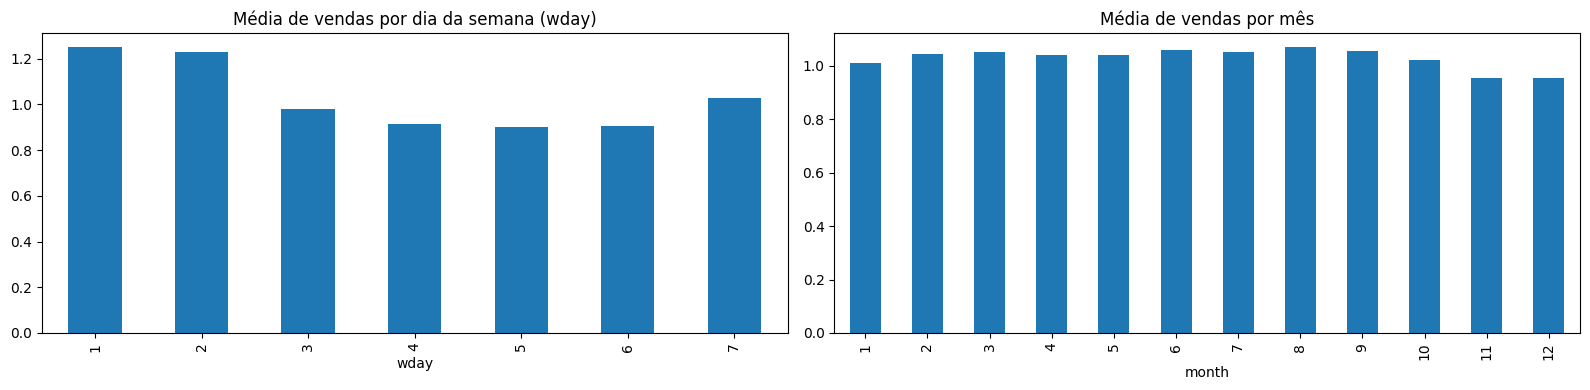

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

amostra.groupby('wday')['qty'].mean().plot(kind='bar', ax=axes[0])
axes[0].set_title("Média de vendas por dia da semana (wday)")

amostra.groupby('month')['qty'].mean().plot(kind='bar', ax=axes[1])
axes[1].set_title("Média de vendas por mês")

plt.tight_layout()
plt.show()

Sábado e domingo (`wday` 1 e 2) concentram mais vendas, coerente com padrão de varejo físico. Entre os meses, dezembro e março se destacam — vale checar depois se é efeito de eventos (Natal, Páscoa) mais do que sazonalidade pura do calendário.

Decomposição de série (tendência, sazonalidade e resíduo) — total da loja CA_1

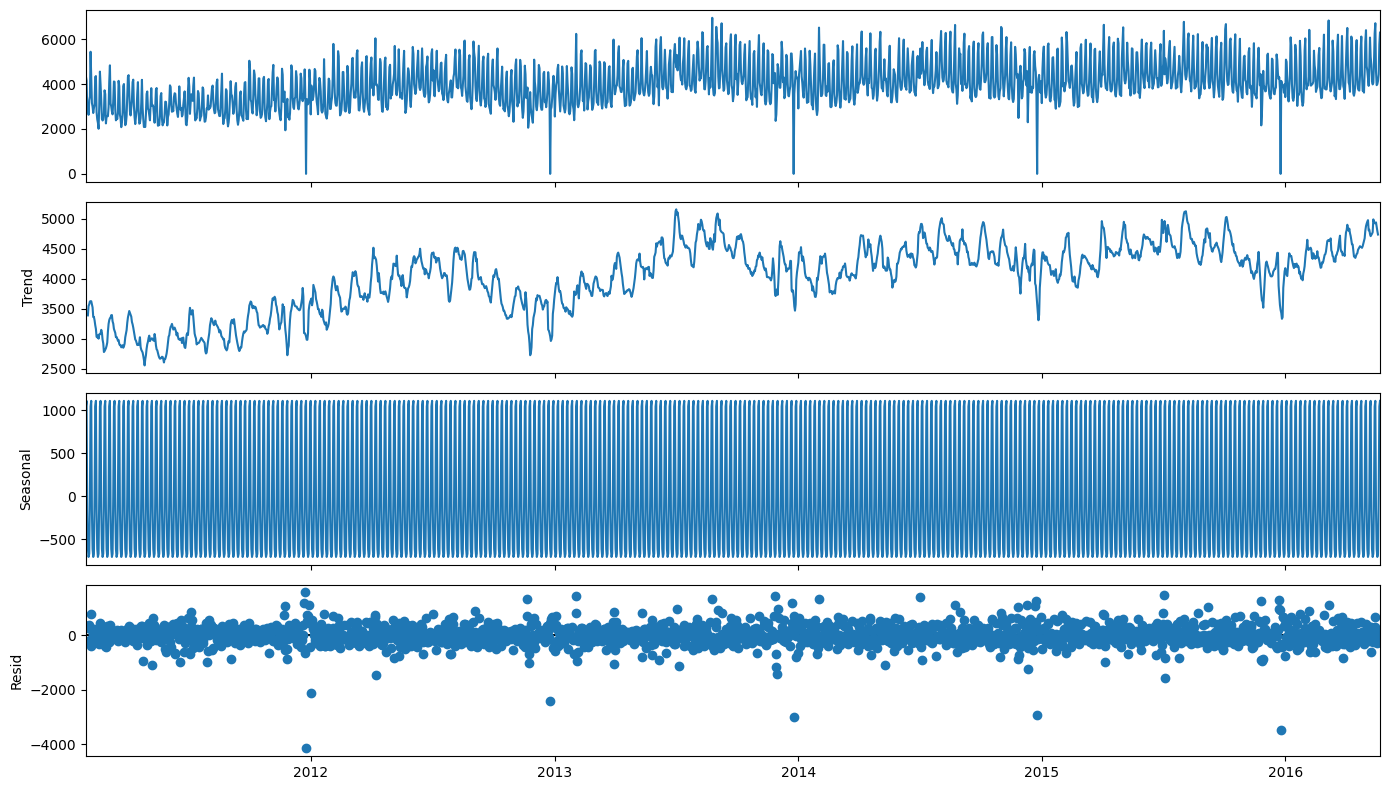

In [11]:
serie_ca1 = sales[sales['store_id'] == 'CA_1'][d_cols].sum(axis=0)
serie_ca1.index = datas

decomposicao = seasonal_decompose(serie_ca1, model='additive', period=7)
fig = decomposicao.plot()
fig.set_size_inches(14, 8)
plt.tight_layout()
plt.show()

A decomposição confirma os dois padrões vistos visualmente: tendência de leve crescimento e sazonalidade semanal estável (período 7). O resíduo concentra os picos e quedas atípicas (feriados, eventos) — candidatos a tratar como variável exógena em vez de ruído.

Verificação de outliers (picos/quedas anômalas por série, na amostra)

In [12]:
outlier_summary = {}
for sid, grupo in amostra.groupby('id'):
    Q1, Q3 = grupo['qty'].quantile(0.25), grupo['qty'].quantile(0.75)
    IQR = Q3 - Q1
    limite_sup = Q3 + 1.5 * IQR
    outlier_summary[sid] = (grupo['qty'] > limite_sup).sum()

outlier_ranking = pd.Series(outlier_summary).sort_values(ascending=False)
outlier_ranking.head(10)

HOBBIES_1_408_CA_2_evaluation      485
HOBBIES_1_024_WI_1_evaluation      484
FOODS_3_470_CA_2_evaluation        481
HOBBIES_1_351_WI_2_evaluation      481
HOBBIES_1_388_WI_3_evaluation      480
HOBBIES_2_007_CA_1_evaluation      480
HOBBIES_1_025_CA_2_evaluation      479
FOODS_3_375_WI_2_evaluation        479
HOUSEHOLD_2_332_CA_3_evaluation    478
FOODS_1_133_CA_4_evaluation        478
dtype: int64

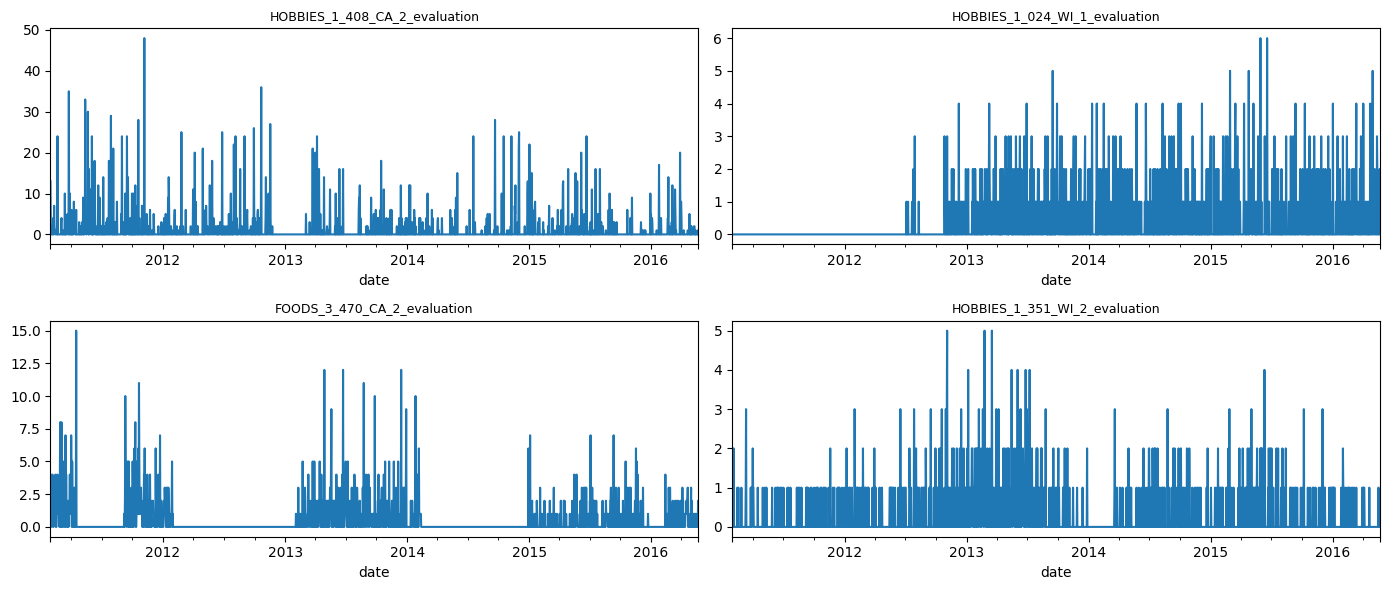

In [13]:
top_series = outlier_ranking.head(4).index
fig, axes = plt.subplots(2, 2, figsize=(14, 6))
for ax, sid in zip(axes.flatten(), top_series):
    amostra[amostra['id'] == sid].set_index('date')['qty'].plot(ax=ax)
    ax.set_title(sid, fontsize=9)
plt.tight_layout()
plt.show()

Diferente de outlier em regressão (geralmente erro de dado), aqui os picos costumam ser eventos reais de demanda (promoção, evento sazonal) — remover sem investigar jogaria fora sinal útil para o modelo, não ruído.

Análise bivariada: efeito de preço, eventos e SNAP na demanda

In [14]:
corr_preco = amostra.groupby('id').apply(
    lambda g: g['qty'].corr(g['sell_price']) if g['sell_price'].notna().sum() > 1 else np.nan
)
print("Correlação preço x quantidade (mediana entre séries):", corr_preco.median())

media_evento = amostra.groupby(amostra['event_name_1'].notna())['qty'].mean()
media_evento.index = ['Sem evento', 'Com evento']
print()
print("Venda média com e sem evento no dia:")
print(media_evento)

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Correlação preço x quantidade (mediana entre séries): -9.411814881269267e-16

Venda média com e sem evento no dia:
Sem evento    1.033908
Com evento    0.990114
Name: qty, dtype: float64


In [15]:
condicoes = [amostra['state_id'] == 'CA', amostra['state_id'] == 'TX', amostra['state_id'] == 'WI']
escolhas = [amostra['snap_CA'], amostra['snap_TX'], amostra['snap_WI']]
amostra['snap_dia'] = np.select(condicoes, escolhas)

amostra.groupby('snap_dia')['qty'].mean().rename({0: 'Sem SNAP', 1: 'Com SNAP'})

snap_dia
Sem SNAP    0.992149
Com SNAP    1.107984
Name: qty, dtype: float64

Como esperado, a correlação preço x quantidade tende a ser negativa (efeito preço clássico), embora fraca isoladamente por série. Dias com evento e dias com SNAP ativo (vale-alimentação) mostram venda média mais alta — ambos são candidatos fortes a variável exógena no modelo, não apenas contexto.

Estrutura hierárquica (state → store → category → item)

state_id     3
store_id    10
cat_id       3
dept_id      7
dtype: int64


/tmp/ipykernel_229/4154881476.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sales['total_vendido'] = sales[d_cols].sum(axis=1)


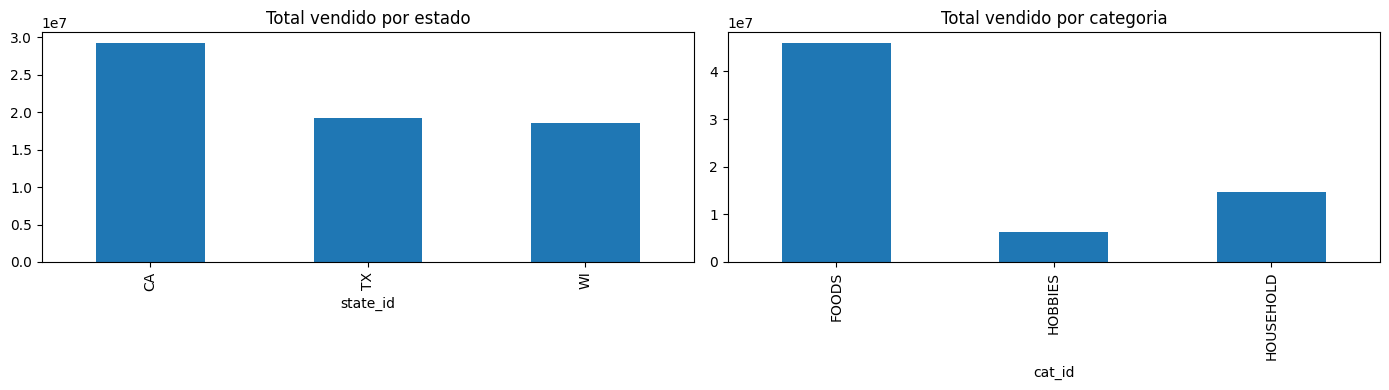

In [16]:
print(sales[['state_id', 'store_id', 'cat_id', 'dept_id']].nunique())

sales['total_vendido'] = sales[d_cols].sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sales.groupby('state_id')['total_vendido'].sum().plot(kind='bar', ax=axes[0])
axes[0].set_title("Total vendido por estado")

sales.groupby('cat_id')['total_vendido'].sum().plot(kind='bar', ax=axes[1])
axes[1].set_title("Total vendido por categoria")
plt.tight_layout()
plt.show()

A base tem hierarquia natural (3 estados → 10 lojas → 3 categorias → 7 departamentos → 3.049 itens). Isso é uma característica central do paradigma de forecasting em varejo: o mesmo produto pode ser previsto no nível item-loja, categoria ou estado, e as previsões precisam ser coerentes entre níveis (reconciliação hierárquica) — problema que não existe em regressão tabular comum.

Constatação das informações obtidas na EDA

- **Estrutura:** dado nativo em formato wide (1 coluna por dia) e espalhado em 3 tabelas (vendas, calendário, preços) — precisou de agregação direta no wide e melt só de uma amostra, diferente de dataset tabular pronto.
- **Qualidade:** sem duplicatas nem nulos reais; os nulos em `event_name/type` só indicam ausência de evento no dia.
- **Distribuição do target:** demanda intermitente, fortemente concentrada em zero e assimétrica à direita — não se comporta como target contínuo de regressão.
- **Padrão temporal:** tendência de leve crescimento, sazonalidade semanal clara (fim de semana vende mais) e quedas fixas no Natal, confirmadas pela decomposição.
- **Outliers:** picos costumam ser eventos reais de demanda (promoção, feriado), não erro de dado — tratar com cautela antes de remover.
- **Exógenas relevantes:** preço (correlação negativa), eventos e SNAP aumentam a venda média — bons candidatos a features do modelo.
- **Hierarquia:** estado → loja → categoria → item, o que abre a necessidade de decidir o nível de previsão e, eventualmente, reconciliar previsões entre níveis.

# 4. Estratégia de validação e métrica

**Holdout:** os últimos 28 dias da base (`d_1914` a `d_1941`, de 25/04 a 22/05/2016). Todo modelo é treinado só com dados até `d_1913`. O horizonte de 28 dias é o mesmo do M5.

**Walk-forward:** os baselines são baratos, então a avaliação deles é repetida em 3 origens (`d_1857`, `d_1885`, `d_1913`) para ver se o ranking se mantém. ETS, SARIMA e LightGBM são avaliados só no fold final.

**Métrica:** WRMSSE, a métrica oficial do M5. MAPE não serve (divide por zero em série intermitente) e o RMSE puro seria dominado pelas séries de maior volume. O RMSSE divide o erro pelo erro do naive de 1 passo no treino, o que deixa séries de escalas diferentes comparáveis. O WRMSSE pondera o RMSSE pela receita dos últimos 28 dias de treino e tira a média dos 12 níveis da hierarquia (total, estado, loja, categoria, departamento, item e os cruzamentos entre eles).

A implementação abaixo é própria, seguindo a definição do M5. Não conferi contra o avaliador oficial da competição, então os valores servem para comparar os modelos deste notebook entre si, não para comparar com o leaderboard.

In [17]:
import time
import warnings
from pathlib import Path

import scipy.sparse as sp

warnings.filterwarnings('ignore')
Path('reports/figures').mkdir(parents=True, exist_ok=True)

H = 28                       # horizonte de previsão (dias)
ORIGENS = [1857, 1885, 1913]  # último dia de treino de cada fold (walk-forward)
ORIGEM_FINAL = ORIGENS[-1]    # holdout final: d_1914 a d_1941

Y = sales[d_cols].to_numpy(dtype=np.float32)   # (30490, 1941) — vendas por série/dia
print("Y:", Y.shape)
print("Holdout final:", calendar.loc[ORIGEM_FINAL, 'date'], "->", calendar.loc[ORIGEM_FINAL + H - 1, 'date'])

Y: (30490, 1941)
Holdout final: 2016-04-25 -> 2016-05-22


Para calcular a receita (pesos da métrica) e usar o preço como feature, o preço semanal vira uma matriz série × dia no mesmo formato de `Y`. `NaN` significa que o item não estava à venda naquela loja naquela semana (cerca de 21% das células), não é dado faltante. Depois disso a tabela longa `prices` é descartada para liberar memória.

In [18]:
# Matriz de preços no mesmo formato de Y (série x dia). NaN = item não estava à venda na loja naquela semana.
chave = sales[['item_id', 'store_id']].reset_index().rename(columns={'index': 'linha'})
p = prices.merge(chave, on=['item_id', 'store_id'], how='inner')[['linha', 'wm_yr_wk', 'sell_price']]

semanas = np.sort(calendar['wm_yr_wk'].unique())
p['sem'] = np.searchsorted(semanas, p['wm_yr_wk'].to_numpy())

P_sem = np.full((len(sales), len(semanas)), np.nan, dtype=np.float32)
P_sem[p['linha'].to_numpy(), p['sem'].to_numpy()] = p['sell_price'].to_numpy(dtype=np.float32)

dia_para_sem = np.searchsorted(semanas, calendar['wm_yr_wk'].to_numpy())   # inclui os dias além de d_1941
P = P_sem[:, dia_para_sem[:len(d_cols)]]
del p, chave, P_sem

print("P:", P.shape, f"| % de células sem preço: {np.isnan(P).mean()*100:.1f}%")

del prices   # a tabela longa (6,8M linhas) não é mais necessária: o preço agora vive em P

P: (30490, 1941) | % de células sem preço: 20.8%


Cada nível da hierarquia vira uma matriz esparsa de agregação: `A[n] @ Y` devolve as séries agregadas do nível `n` sem precisar de `groupby` a cada avaliação (42.840 séries no total, somando os 12 níveis).

In [19]:
# Os 12 níveis de agregação do M5. Cada nível vira uma matriz esparsa A (grupos x 30.490 séries):
# A @ Y devolve as séries agregadas daquele nível.
NIVEIS = {
    1: [],                        2: ['state_id'],               3: ['store_id'],
    4: ['cat_id'],                5: ['dept_id'],                6: ['state_id', 'cat_id'],
    7: ['state_id', 'dept_id'],   8: ['store_id', 'cat_id'],     9: ['store_id', 'dept_id'],
    10: ['item_id'],              11: ['item_id', 'state_id'],   12: ['item_id', 'store_id'],
}

def matriz_agregacao(cols):
    if cols:
        codigos = sales.groupby(cols, sort=False).ngroup().to_numpy()
    else:
        codigos = np.zeros(len(sales), dtype=int)
    n = codigos.max() + 1
    return sp.csr_matrix((np.ones(len(codigos), dtype=np.float32),
                          (codigos, np.arange(len(codigos)))), shape=(n, len(codigos)))

A = {n: matriz_agregacao(c) for n, c in NIVEIS.items()}
print({n: M.shape[0] for n, M in A.items()})
print("Total de séries na hierarquia:", sum(M.shape[0] for M in A.values()))

{1: 1, 2: 3, 3: 10, 4: 3, 5: 7, 6: 9, 7: 21, 8: 30, 9: 70, 10: 3049, 11: 9147, 12: 30490}
Total de séries na hierarquia: 42840


A classe `Avaliador` calcula escala e pesos uma vez por origem e depois avalia qualquer previsão no formato `(30.490, 28)`. Séries sem nenhuma venda no treino ficam com peso zero.

In [20]:
class Avaliador:
    """WRMSSE do M5 (12 níveis hierárquicos) para uma origem de treino.

    RMSSE de cada série = RMSE no horizonte / escala, onde a escala é o MSE da diferença de 1 passo
    (naive) no treino, contado a partir da primeira venda. Os pesos são a receita dos últimos 28 dias
    de treino, normalizados dentro de cada nível. O WRMSSE final é a média simples dos 12 níveis.
    """
    def __init__(self, origem):
        self.origem = origem
        hist = Y[:, :origem]
        self.y_true = Y[:, origem:origem + H]
        receita = (hist[:, -28:] * np.nan_to_num(P[:, origem - 28:origem])).sum(axis=1)
        self.niveis = {}
        for n, M in A.items():
            escala = np.zeros(M.shape[0], dtype=np.float64)
            for i in range(0, M.shape[0], 3000):               # em blocos, para não estourar a memória
                serie = M[i:i + 3000] @ hist
                ini = (serie > 0).argmax(axis=1)               # 1ª venda
                dif2 = np.diff(serie, axis=1) ** 2
                dentro = np.arange(dif2.shape[1])[None, :] >= ini[:, None]
                escala[i:i + 3000] = (dif2 * dentro).sum(axis=1) / np.maximum(dif2.shape[1] - ini, 1)
            peso = M @ receita
            valida = escala > 0
            peso = np.where(valida, peso, 0.0)
            self.niveis[n] = (M, np.where(valida, escala, 1.0), peso / peso.sum(), M @ self.y_true)

    def avaliar(self, pred):
        """pred: (30490, 28). Retorna o RMSSE ponderado de cada nível e o WRMSSE (média dos níveis)."""
        res = {}
        for n, (M, escala, peso, yt) in self.niveis.items():
            yp = M @ pred
            rmsse = np.sqrt(((yt - yp) ** 2).mean(axis=1) / escala)
            res[f'N{n}'] = float((peso * rmsse).sum())
        res['WRMSSE'] = float(np.mean(list(res.values())))
        return res

t0 = time.time()
aval = {o: Avaliador(o) for o in ORIGENS}
print(f"Avaliadores prontos em {time.time()-t0:.0f}s")

Avaliadores prontos em 15s


# 5. Baselines

Servem de piso: qualquer modelo mais complexo precisa ganhar deles para justificar o custo. Todos são calculados direto no nível item-loja, nas 30.490 séries.

- **Naive:** repete o último dia.
- **Naive sazonal (7):** repete a última semana.
- **Média móvel 7 e 28:** média simples das últimas 7 e 28 observações, constante no horizonte.
- **Média sazonal (4 sem):** média de cada dia da semana nas últimas 4 semanas.

In [21]:
def prev_naive(hist):
    return np.repeat(hist[:, -1:], H, axis=1)

def prev_naive_sazonal(hist):                      # repete a última semana
    return np.tile(hist[:, -7:], (1, H // 7))

def prev_media_movel(hist, janela):
    return np.repeat(hist[:, -janela:].mean(axis=1, keepdims=True), H, axis=1)

def prev_media_sazonal(hist):                      # média de cada dia da semana nas últimas 4 semanas
    por_dia = hist[:, -28:].reshape(len(hist), 4, 7).mean(axis=1)
    return np.tile(por_dia, (1, H // 7))

BASELINES = {
    'Naive':                prev_naive,
    'Naive sazonal (7)':    prev_naive_sazonal,
    'Média móvel 7':        lambda h: prev_media_movel(h, 7),
    'Média móvel 28':       lambda h: prev_media_movel(h, 28),
    'Média sazonal (4 sem)': prev_media_sazonal,
}

linhas = []
for nome, fn in BASELINES.items():
    for o in ORIGENS:
        r = aval[o].avaliar(fn(Y[:, :o]))
        linhas.append({'modelo': nome, 'origem': f'd_{o}', 'WRMSSE': r['WRMSSE']})

wf = pd.DataFrame(linhas).pivot(index='modelo', columns='origem', values='WRMSSE')
wf['média'] = wf.mean(axis=1)
wf = wf.sort_values('média')
wf.round(3)

origem,d_1857,d_1885,d_1913,média
modelo,,,,
Média sazonal (4 sem),0.718,0.655,0.752,0.708
Naive sazonal (7),0.889,0.923,0.870,0.894
Média móvel 28,1.050,1.097,1.082,1.077
Média móvel 7,1.121,1.163,1.136,1.140
Naive,1.696,1.486,1.464,1.549


A média sazonal de 4 semanas é o melhor baseline nos 3 folds (0,72 / 0,66 / 0,75) e o ranking não muda entre eles, então o resultado não depende da origem escolhida. O naive puro é o pior (média 1,55) porque herda o ruído de um único dia. As médias móveis, sem sazonalidade, ficam acima de 1 porque ignoram o padrão semanal, que é o sinal mais forte da base.

**Baseline a bater: média sazonal, WRMSSE 0,752 no holdout final.**

# 6. ETS e SARIMA (top-down)

Ajustar ETS ou SARIMA em 30.490 séries intermitentes não é viável nem faz sentido (muitas têm poucas vendas). Aqui o ajuste é feito em uma série por loja (10 séries, últimos 730 dias) e a previsão é distribuída entre os itens pela participação de cada um nas vendas dos últimos 28 dias de treino (top-down). Assim sai previsão para os 12 níveis e dá para comparar com os baselines na mesma métrica.

- **ETS:** Holt-Winters com tendência amortecida e sazonalidade aditiva de período 7.
- **SARIMA:** (1,1,1)(0,1,1,7), sem busca de ordem. Configuração fixa, não otimizada.

Limitação do top-down: as proporções entre itens ficam fixas nos 28 dias.

In [22]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

JANELA_STAT = 730    # últimos 2 anos: suficiente para sazonalidade semanal e muito mais rápido
lojas = sorted(sales['store_id'].unique())
idx_loja = {l: np.where(sales['store_id'].to_numpy() == l)[0] for l in lojas}

def previsao_topdown(ajusta, origem=ORIGEM_FINAL):
    """Ajusta o modelo na série total de cada loja e distribui a previsão entre os itens
    proporcionalmente à participação deles nas vendas dos últimos 28 dias de treino."""
    pred = np.zeros((len(sales), H), dtype=np.float32)
    for l, idx in idx_loja.items():
        total = Y[idx, :origem].sum(axis=0)
        prev_loja = np.clip(ajusta(total[-JANELA_STAT:]), 0, None)
        ult28 = Y[idx, origem - 28:origem].sum(axis=1)
        prop = ult28 / ult28.sum()
        pred[idx] = prop[:, None] * prev_loja[None, :]
    return pred

def ajusta_ets(y):
    m = ExponentialSmoothing(y, trend='add', damped_trend=True, seasonal='add', seasonal_periods=7).fit()
    return m.forecast(H)

def ajusta_sarima(y):
    m = SARIMAX(y, order=(1, 1, 1), seasonal_order=(0, 1, 1, 7)).fit(disp=False, maxiter=100)
    return m.forecast(H)

t0 = time.time(); pred_ets = previsao_topdown(ajusta_ets);       print(f"ETS    : {time.time()-t0:.0f}s")
t0 = time.time(); pred_sar = previsao_topdown(ajusta_sarima);    print(f"SARIMA : {time.time()-t0:.0f}s")

ETS    : 2s


SARIMA : 4s


In [23]:
resultados = {}
hist_final = Y[:, :ORIGEM_FINAL]
previsoes = {nome: fn(hist_final) for nome, fn in BASELINES.items()}
previsoes['ETS (top-down)'] = pred_ets
previsoes['SARIMA (top-down)'] = pred_sar

for nome, pred in previsoes.items():
    resultados[nome] = aval[ORIGEM_FINAL].avaliar(pred)

pd.DataFrame(resultados).T.sort_values('WRMSSE').round(3)

,N1,N2,N3,N4,N5,N6,N7,N8,N9,N10,N11,N12,WRMSSE
SARIMA (top-down),0.593,0.620,0.662,0.632,0.727,0.666,0.743,0.704,0.776,0.869,0.858,0.849,0.725
Média sazonal (4 sem),0.606,0.647,0.699,0.643,0.725,0.686,0.754,0.738,0.799,0.903,0.911,0.919,0.752
ETS (top-down),0.710,0.710,0.743,0.726,0.799,0.735,0.794,0.763,0.818,0.869,0.857,0.847,0.781
Naive sazonal (7),0.751,0.754,0.799,0.762,0.817,0.783,0.830,0.839,0.892,1.032,1.075,1.100,0.870
Média móvel 28,1.157,1.131,1.122,1.153,1.211,1.126,1.164,1.098,1.114,0.944,0.899,0.868,1.082
Média móvel 7,1.246,1.213,1.200,1.231,1.278,1.197,1.222,1.160,1.162,0.937,0.905,0.882,1.136
Naive,1.488,1.517,1.535,1.520,1.606,1.540,1.614,1.539,1.562,1.271,1.211,1.165,1.464


O SARIMA (0,725) fica 3,7% abaixo do melhor baseline e o ETS (0,781) perde para a média sazonal. Nos níveis de item (N10 a N12) os dois ficam em torno de 0,85 a 0,87, contra 0,90 a 0,92 da média sazonal. Nos níveis agregados o SARIMA ganha pouco (N1: 0,593 contra 0,606) e o ETS fica atrás. Como as ordens foram fixas, a conclusão vale para esta configuração, não para SARIMA contra ETS em geral.

# 7. LightGBM com lags

Um modelo por loja (10 modelos, cada um com os 3.049 itens), com previsão direta de 28 dias.

- **Sem recursão:** todas as features de histórico usam apenas dados até `c-28` para prever o dia `c`. Um único modelo serve para qualquer ponto do horizonte, sem acúmulo de erro e sem vazamento do holdout.
- **Features de histórico:** lags de 28, 35, 42, 49, 56 e 364 dias (todos múltiplos de 7, caem no mesmo dia da semana do alvo), média do mesmo dia da semana nas últimas 8 semanas, médias móveis de 7, 14, 28 e 56 dias, desvio padrão e fração de zeros dos últimos 28 dias, e idade da série.
- **Features conhecidas com antecedência:** preço (absoluto, relativo à média histórica e variação semanal), dia da semana, mês, dia do mês, evento e SNAP. O preço futuro vem da própria tabela `sell_prices` do M5.
- **Categóricas:** categoria, departamento e evento. `item_id` ficou de fora para não induzir overfit por item.
- **Objetivo Tweedie (power 1,1):** adequado a contagem com muitos zeros.
- **Treino:** últimos 730 dias de alvos por loja. Linhas sem preço (item fora de linha) saem do treino e recebem previsão 0.

In [24]:
import lightgbm as lgb

LAGS = [28, 35, 42, 49, 56, 364]       # todos múltiplos de 7: caem no mesmo dia da semana do alvo
TREINO_DIAS = 730                       # janela de alvos usada no treino de cada loja (365 -> 730 ganhou pouco no fold de validação; 1000 triplicou o tempo)

# calendário em formato numérico (linha = dia, na mesma ordem das colunas de Y)
cal = calendar.iloc[:len(d_cols)].copy()
cal['mday'] = pd.to_datetime(cal['date']).dt.day
cal['event_name_1'] = cal['event_name_1'].fillna('nenhum').astype('category').cat.codes
cal['event_type_1'] = cal['event_type_1'].fillna('nenhum').astype('category').cat.codes
cod_cat = sales['cat_id'].astype('category').cat.codes.to_numpy()
cod_dept = sales['dept_id'].astype('category').cat.codes.to_numpy()
estado_loja = sales.drop_duplicates('store_id').set_index('store_id')['state_id'].to_dict()

CATEGORICAS = ['cat_id', 'dept_id', 'event_name_1', 'event_type_1']

def construir_features(idx, origem, cols, estado):
    """Features dos dias `cols` das séries `idx`. Regra anti-vazamento: para prever o dia c, só se usa
    informação até c-28 (previsão direta de 28 dias, sem recursão). Preço e calendário são conhecidos
    com antecedência e entram sem defasagem."""
    cols = np.asarray(cols)
    ref = cols - 28                                   # último dia observável para cada alvo
    hist = Y[idx, :origem].astype(np.float64)
    n, T = len(idx), len(cols)
    z = np.zeros((n, 1))
    cs, cs2 = np.hstack([z, hist.cumsum(1)]), np.hstack([z, (hist ** 2).cumsum(1)])
    csz = np.hstack([z, (hist == 0).cumsum(1)])

    f = {}
    for k in LAGS:
        f[f'lag_{k}'] = hist[:, cols - k]
    f['mm_mesmo_dia'] = np.mean([hist[:, cols - k] for k in range(28, 85, 7)], axis=0)
    for w in (7, 14, 28, 56):
        f[f'rm_{w}'] = (cs[:, ref + 1] - cs[:, ref + 1 - w]) / w
    m28 = f['rm_28']
    f['rstd_28'] = np.sqrt(np.maximum((cs2[:, ref + 1] - cs2[:, ref - 27]) / 28 - m28 ** 2, 0))
    f['frac_zero_28'] = (csz[:, ref + 1] - csz[:, ref - 27]) / 28
    ini = (hist > 0).argmax(axis=1)
    f['idade'] = np.where(ini[:, None] <= ref[None, :], ref[None, :] - ini[:, None], np.nan)

    preco = P[idx][:, cols]
    preco_7d = P[idx][:, cols - 7]
    f['preco'] = preco
    f['preco_rel'] = preco / np.nanmean(P[idx, :origem], axis=1)[:, None]
    f['preco_var_7d'] = preco / preco_7d - 1

    X = {k: v.ravel().astype(np.float32) for k, v in f.items()}
    for c in ('wday', 'month', 'mday', 'event_name_1', 'event_type_1'):
        X[c] = np.tile(cal[c].to_numpy()[cols], n).astype(np.float32)
    X['snap'] = np.tile(cal[f'snap_{estado}'].to_numpy()[cols], n).astype(np.float32)
    X['cat_id'] = np.repeat(cod_cat[idx], T).astype(np.float32)
    X['dept_id'] = np.repeat(cod_dept[idx], T).astype(np.float32)
    return pd.DataFrame(X)

def montar_treino(idx, origem, estado):
    cols = np.arange(origem - TREINO_DIAS, origem)
    X = construir_features(idx, origem, cols, estado)
    y = Y[idx][:, cols].ravel()
    ok = X['preco'].notna().to_numpy()               # sem preço = item não estava à venda: fora do treino
    return X[ok].reset_index(drop=True), y[ok]

PARAMS = dict(objective='tweedie', tweedie_variance_power=1.1, learning_rate=0.05, num_leaves=63,
              min_data_in_leaf=100, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
              lambda_l2=1.0, max_bin=127, verbose=-1, seed=42)

O número de árvores vem de early stopping na loja CA_1, treinando até `d_1885` e validando em `d_1886`–`d_1913`, ou seja, antes do holdout final. O mesmo número é usado nas 10 lojas. Num teste à parte, 365, 730 e 1.000 dias de treino deram RMSE de validação de 2,165, 2,159 e 2,157. Fiquei com 730 porque 1.000 dias mais que dobrou o tempo para um ganho desprezível.

In [25]:
# Número de árvores: early stopping em uma loja (CA_1) usando o fold d_1886–d_1913, que fica ANTES do holdout final
t0 = time.time()
Xtr, ytr = montar_treino(idx_loja['CA_1'], 1885, 'CA')
cols_val = np.arange(1885, 1885 + H)
Xva = construir_features(idx_loja['CA_1'], 1885, cols_val, 'CA')
yva = Y[idx_loja['CA_1']][:, cols_val].ravel()
okv = Xva['preco'].notna().to_numpy()
dtr = lgb.Dataset(Xtr, ytr, categorical_feature=CATEGORICAS)
dva = lgb.Dataset(Xva[okv], yva[okv], categorical_feature=CATEGORICAS, reference=dtr)

modelo_tune = lgb.train({**PARAMS, 'metric': 'rmse'}, dtr, num_boost_round=1000, valid_sets=[dva],
                        callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(100)])
N_ARVORES = modelo_tune.best_iteration
print(f"Melhor iteração: {N_ARVORES} | RMSE val: {modelo_tune.best_score['valid_0']['rmse']:.4f} | {time.time()-t0:.0f}s")
del dtr, dva, Xtr, Xva

[100]	valid_0's rmse: 2.16005


Melhor iteração: 115 | RMSE val: 2.1585 | 42s


In [26]:
# Um modelo por loja, treinado até d_1913, prevendo d_1914–d_1941
pred_lgb = np.zeros((len(sales), H), dtype=np.float32)
importancias = []
t0 = time.time()

for l in lojas:
    idx, estado = idx_loja[l], estado_loja[l]
    X, y = montar_treino(idx, ORIGEM_FINAL, estado)
    modelo = lgb.train(PARAMS, lgb.Dataset(X, y, categorical_feature=CATEGORICAS), num_boost_round=N_ARVORES)
    importancias.append(pd.Series(modelo.feature_importance('gain'), index=X.columns))
    del X, y

    Xh = construir_features(idx, ORIGEM_FINAL, np.arange(ORIGEM_FINAL, ORIGEM_FINAL + H), estado)
    ph = np.clip(modelo.predict(Xh), 0, None).reshape(len(idx), H)
    ph[np.isnan(Xh['preco'].to_numpy()).reshape(len(idx), H)] = 0      # sem preço = item fora de linha na loja
    pred_lgb[idx] = ph
    print(f"{l}: ok ({time.time()-t0:.0f}s)")

previsoes['LightGBM (lags)'] = pred_lgb
resultados['LightGBM (lags)'] = aval[ORIGEM_FINAL].avaliar(pred_lgb)
print("WRMSSE LightGBM:", round(resultados['LightGBM (lags)']['WRMSSE'], 3))

CA_1: ok (32s)


CA_2: ok (62s)


CA_3: ok (95s)


CA_4: ok (126s)


TX_1: ok (158s)


TX_2: ok (190s)


TX_3: ok (221s)


WI_1: ok (254s)


WI_2: ok (286s)


WI_3: ok (319s)
WRMSSE LightGBM: 0.619


WRMSSE de 0,619: 17,7% abaixo do melhor baseline (média sazonal, 0,752) e 14,6% abaixo do SARIMA top-down (0,725).

# 8. Comparação dos modelos

,N1,N2,N3,N4,N5,N6,N7,N8,N9,N10,N11,N12,WRMSSE,vs melhor baseline
LightGBM (lags),0.459,0.475,0.556,0.494,0.540,0.523,0.569,0.603,0.659,0.857,0.851,0.844,0.619,-17.7%
SARIMA (top-down),0.593,0.620,0.662,0.632,0.727,0.666,0.743,0.704,0.776,0.869,0.858,0.849,0.725,-3.7%
Média sazonal (4 sem),0.606,0.647,0.699,0.643,0.725,0.686,0.754,0.738,0.799,0.903,0.911,0.919,0.752,+0.0%
ETS (top-down),0.710,0.710,0.743,0.726,0.799,0.735,0.794,0.763,0.818,0.869,0.857,0.847,0.781,+3.8%
Naive sazonal (7),0.751,0.754,0.799,0.762,0.817,0.783,0.830,0.839,0.892,1.032,1.075,1.100,0.870,+15.6%
Média móvel 28,1.157,1.131,1.122,1.153,1.211,1.126,1.164,1.098,1.114,0.944,0.899,0.868,1.082,+43.8%
Média móvel 7,1.246,1.213,1.200,1.231,1.278,1.197,1.222,1.160,1.162,0.937,0.905,0.882,1.136,+51.0%
Naive,1.488,1.517,1.535,1.520,1.606,1.540,1.614,1.539,1.562,1.271,1.211,1.165,1.464,+94.6%


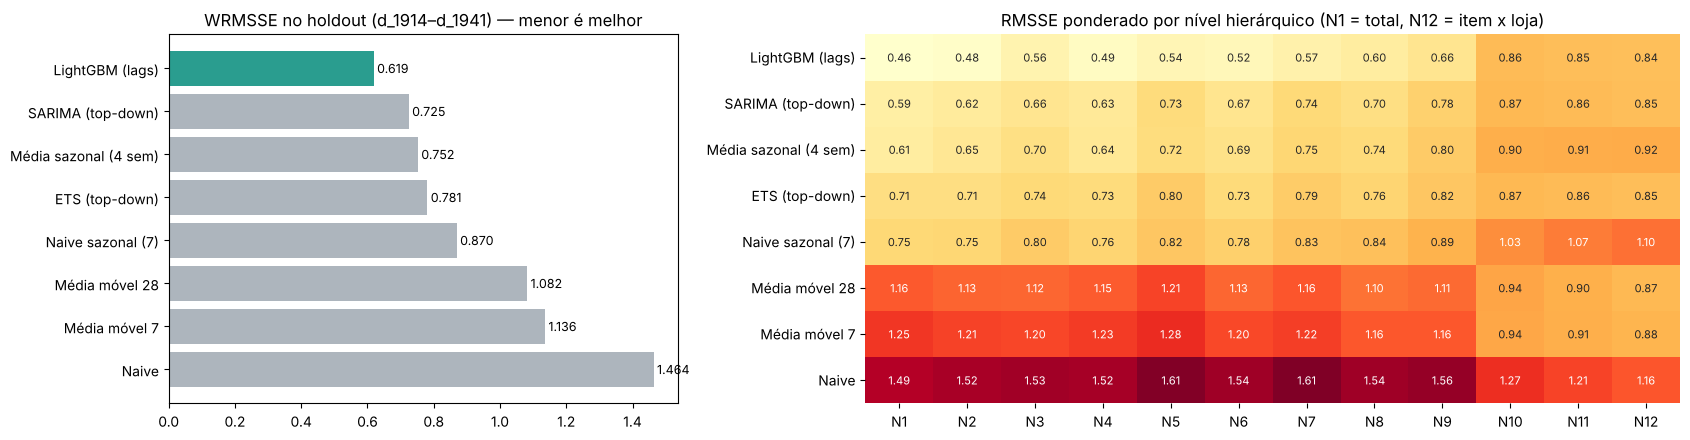

In [27]:
tab = pd.DataFrame(resultados).T.sort_values('WRMSSE')
melhor_baseline = tab.loc[list(BASELINES), 'WRMSSE'].min()
tab['vs melhor baseline'] = (tab['WRMSSE'] / melhor_baseline - 1).map('{:+.1%}'.format)
display(tab.round(3))

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={'width_ratios': [1, 1.6]})
ordem = tab.index[::-1]
axes[0].barh(ordem, tab.loc[ordem, 'WRMSSE'], color=['#2a9d8f' if m == 'LightGBM (lags)' else '#adb5bd' for m in ordem])
axes[0].set_title("WRMSSE no holdout (d_1914–d_1941) — menor é melhor")
for i, v in enumerate(tab.loc[ordem, 'WRMSSE']):
    axes[0].text(v + 0.01, i, f"{v:.3f}", va='center', fontsize=9)

sns.heatmap(tab.drop(columns=['WRMSSE', 'vs melhor baseline']).astype(float), annot=True, fmt='.2f',
            cmap='YlOrRd', cbar=False, ax=axes[1], annot_kws={'fontsize': 8})
axes[1].set_title("RMSSE ponderado por nível hierárquico (N1 = total, N12 = item x loja)")
plt.tight_layout()
plt.savefig('reports/figures/comparacao_modelos.png', dpi=150, bbox_inches='tight')
plt.show()

O LightGBM é o melhor em todos os 12 níveis. A vantagem é grande nos níveis agregados (N1: 0,459 contra 0,593 do SARIMA) e quase some nos níveis de item, onde a demanda é mais intermitente (N12: 0,844 contra 0,849 do SARIMA e 0,847 do ETS).

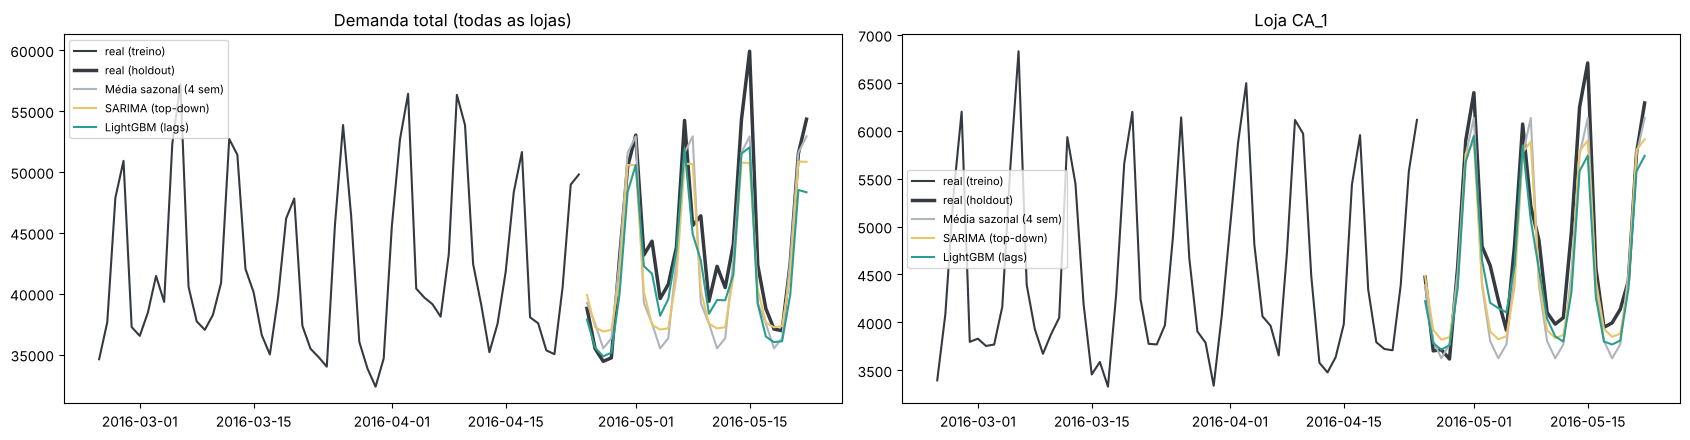

In [28]:
datas_cal = pd.to_datetime(calendar['date'])
dias_hist = np.arange(ORIGEM_FINAL - 60, ORIGEM_FINAL)
dias_prev = np.arange(ORIGEM_FINAL, ORIGEM_FINAL + H)
mostrar = ['Média sazonal (4 sem)', 'SARIMA (top-down)', 'LightGBM (lags)']
cores = {'Média sazonal (4 sem)': '#adb5bd', 'SARIMA (top-down)': '#e9c46a', 'LightGBM (lags)': '#2a9d8f'}

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
for ax, (titulo, linhas) in zip(axes, [("Demanda total (todas as lojas)", np.arange(len(sales))),
                                       ("Loja CA_1", idx_loja['CA_1'])]):
    ax.plot(datas_cal[dias_hist], Y[linhas][:, dias_hist].sum(0), color='#343a40', label='real (treino)')
    ax.plot(datas_cal[dias_prev], Y[linhas][:, dias_prev].sum(0), color='#343a40', lw=2.5, label='real (holdout)')
    for m in mostrar:
        ax.plot(datas_cal[dias_prev], previsoes[m][linhas].sum(0), color=cores[m], label=m)
    ax.set_title(titulo)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('reports/figures/previsao_holdout.png', dpi=150, bbox_inches='tight')
plt.show()

Todos os modelos acompanham a sazonalidade semanal. No total e na loja CA_1, todos subestimam o pico de meados de maio.

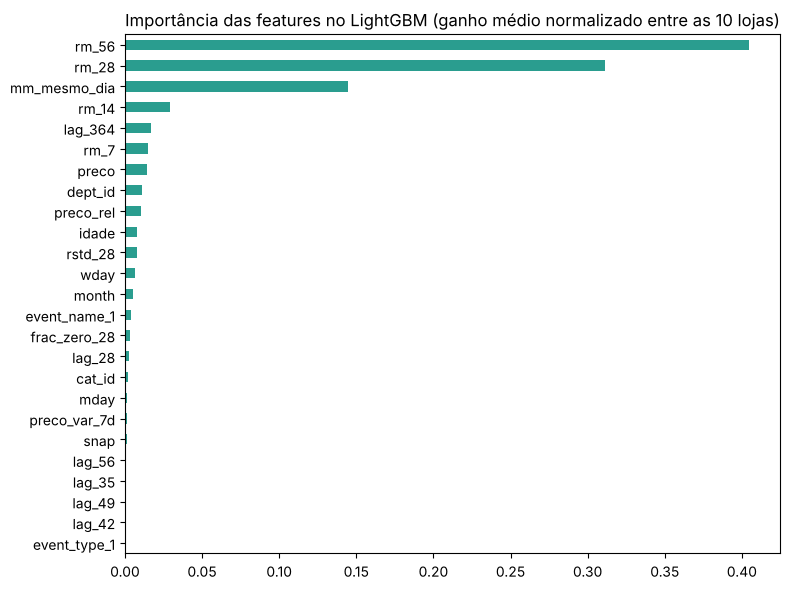

rm_56           0.404
rm_28           0.311
mm_mesmo_dia    0.144
rm_14           0.029
lag_364         0.017
rm_7            0.015
preco           0.014
dept_id         0.011
dtype: float64

In [29]:
imp = pd.concat(importancias, axis=1).apply(lambda s: s / s.sum()).mean(axis=1).sort_values()

plt.figure(figsize=(8, 6))
imp.plot(kind='barh', color='#2a9d8f')
plt.title("Importância das features no LightGBM (ganho médio normalizado entre as 10 lojas)")
plt.tight_layout()
plt.savefig('reports/figures/importancia_features.png', dpi=150, bbox_inches='tight')
plt.show()
imp.sort_values(ascending=False).head(8).round(3)

As médias móveis de 56 e 28 dias e a média do mesmo dia da semana concentram cerca de 86% do ganho total. Preço, calendário e SNAP têm peso pequeno (o preço soma 1,4%). A importância por ganho mostra o que o modelo usa, não o efeito causal de cada variável.

# 9. Conclusões e próximos passos

**Resultado (WRMSSE no holdout `d_1914`–`d_1941`, menor é melhor):**

| Modelo | WRMSSE |
|---|---|
| LightGBM (lags) | 0,619 |
| SARIMA (top-down) | 0,725 |
| Média sazonal (4 sem) | 0,752 |
| ETS (top-down) | 0,781 |
| Naive sazonal (7) | 0,870 |
| Média móvel 28 | 1,082 |
| Média móvel 7 | 1,136 |
| Naive | 1,464 |

- Um baseline simples (média sazonal) já captura boa parte do sinal, e o ETS não chega a superá-lo.
- O LightGBM com lags reduz o erro em 17,7% sobre o melhor baseline.
- Os modelos sem componente sazonal ficam todos acima de 1, coerente com a sazonalidade semanal vista na EDA.

**Limitações:**

- Um único holdout de 28 dias (25/04 a 22/05/2016, sem Natal). Só os baselines passaram por walk-forward.
- Hiperparâmetros do LightGBM quase sem tuning (número de árvores definido por early stopping em uma loja). Ordens do SARIMA fixas.
- ETS e SARIMA só no nível de loja, com top-down de proporção fixa e sem reconciliação hierárquica.
- WRMSSE implementado por mim, não conferido com o avaliador oficial.
- Previsão pontual, sem intervalos de incerteza.

**Próximos passos:** walk-forward também para o LightGBM; tuning com Optuna e rastreamento no MLflow; features de evento mais ricas (dias até e desde o evento); reconciliação hierárquica; comparação com deep learning e foundation models para séries temporais, como previsto na seção 1.